In [1]:
!pip -q install -U pillow jellyfish rapidfuzz sentence-transformers pdfplumber

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 356.4/356.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 29.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 36.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


# **Install and load data**

In [3]:
import numpy as np, jellyfish, re, pandas as pd, pdfplumber, matplotlib.pyplot as plt, seaborn as sns
from rapidfuzz.distance import Levenshtein
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

import os
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"

import nltk
try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True   # only exists in some NLTK versions
except AttributeError:
    pass

from nltk.corpus import wordnet as wn

print(nltk.download("wordnet"))
print(nltk.download("omw-1.4"))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True
True


In [5]:
import os
if os.path.exists('algospeak_dataset.csv'):
    df = pd.read_csv('algospeak_dataset.csv')
else:
    rows = []
    with pdfplumber.open('Moskal & Supernak; algospeak dataset.pdf') as pdf:
        for page in pdf.pages:
            for table in page.extract_tables():
                for row in table:
                    cells = [re.sub(r'\s+', ' ', c).strip() for c in row if c and c.strip()]
                    cells = [c for c in cells if not c.isdigit()]
                    if len(cells) >= 2:
                        rows.append(cells[:2])
    df = pd.DataFrame(rows, columns=['algospeak', 'meaning']).drop_duplicates()
    df = df[df.algospeak.str.lower() != 'algospeak'].reset_index(drop=True)
    df.to_csv('algospeak_dataset.csv', index=False)

print(f'Total dataset rows: {len(df)}')
df.head(10)


(550, 2)


,algospeak,meaning
0,🇮🇱,Israel
1,🇵🇸,Palestine
2,🏳,gay / queer
3,🌈,gay / LGBTQ
4,✡,Jewish
5,🍉,Palestine
6,🌻,Ukraine
7,🌽,porn
8,🍃,weed
9,❄,cocaine


# **Feature Extraction**

In [6]:
LEET = {"4":"a","3":"e","1":"i","0":"o","5":"s","7":"t","@":"a","$":"s","!":"i","8":"b"}
EMOJI = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF]")
letters = lambda s: re.sub(r"[^a-z]", "", s.lower())
unleet  = lambda s: letters("".join(LEET.get(c, c) for c in s.lower()))
sim     = lambda a, b: Levenshtein.normalized_similarity(a, b) if (a or b) else 0
syl     = lambda s: len(re.findall(r"[aeiouy]+", s))

# semantic similarity between algospeak and its decoded meaning
emb = SentenceTransformer("all-MiniLM-L6-v2")
Ea = emb.encode(df.algospeak.tolist(), normalize_embeddings=True)
Em = emb.encode(df.meaning.tolist(),   normalize_embeddings=True)
cos = (Ea * Em).sum(axis=1)

def extract(alg, meaning, c):
    target = letters(re.split(r"[;,(/]", meaning)[0])      # the decoded term
    a = unleet(alg)
    words = alg.split()
    initials = "".join(w[0].lower() for w in meaning.split())
    return {
        # Orthographic
        "length":        len(alg),
        "digit_ratio":   sum(ch.isdigit() for ch in alg) / max(1, len(alg)),
        "symbol_ratio":  sum(not ch.isalnum() and not ch.isspace() for ch in alg) / max(1, len(alg)),
        "has_emoji":     int(bool(EMOJI.search(alg))),
        "edit_sim":      sim(a, target),
        # Phonetic
        "phonetic_sim":  sim(jellyfish.metaphone(a), jellyfish.metaphone(target)),
        "same_sound":    int(jellyfish.metaphone(a) == jellyfish.metaphone(target) and a != ""),
        "syllable_diff": syl(a) - syl(target),
        # Morphological
        "n_tokens":      len(words),
        "is_acronym":    int(len(a) >= 2 and a == initials),
        "is_clipping":   int(0 < len(a) < len(target) and target.startswith(a)),
        "is_real_word":  int(all(len(wn.synsets(letters(w))) > 0 for w in words)),
        # Semantic
        "meaning_sim":   c,
        "meaning_words": len(meaning.split()),
    }

feat = pd.DataFrame([extract(a, m, c) for a, m, c in zip(df.algospeak, df.meaning, cos)])
feat.to_csv("feature_matrix.csv", index=False)
feat.describe().T.round(2)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,count,mean,std,min,25%,50%,75%,max
length,550.0,7.34,4.37,1.00,5.00,7.00,9.00,42.0
digit_ratio,550.0,0.04,0.09,0.00,0.00,0.00,0.00,0.5
symbol_ratio,550.0,0.17,0.27,0.00,0.00,0.00,0.20,1.0
has_emoji,550.0,0.14,0.35,0.00,0.00,0.00,0.00,1.0
edit_sim,550.0,0.59,0.36,0.00,0.25,0.67,1.00,1.0
phonetic_sim,550.0,0.64,0.38,0.00,0.33,0.75,1.00,1.0
same_sound,550.0,0.42,0.49,0.00,0.00,0.00,1.00,1.0
syllable_diff,550.0,-0.37,1.55,-6.00,-1.00,0.00,0.00,11.0
n_tokens,550.0,1.38,0.76,1.00,1.00,1.00,2.00,8.0
is_acronym,550.0,0.01,0.09,0.00,0.00,0.00,0.00,1.0


# **Feature Distributions**

> Normalization, PCA



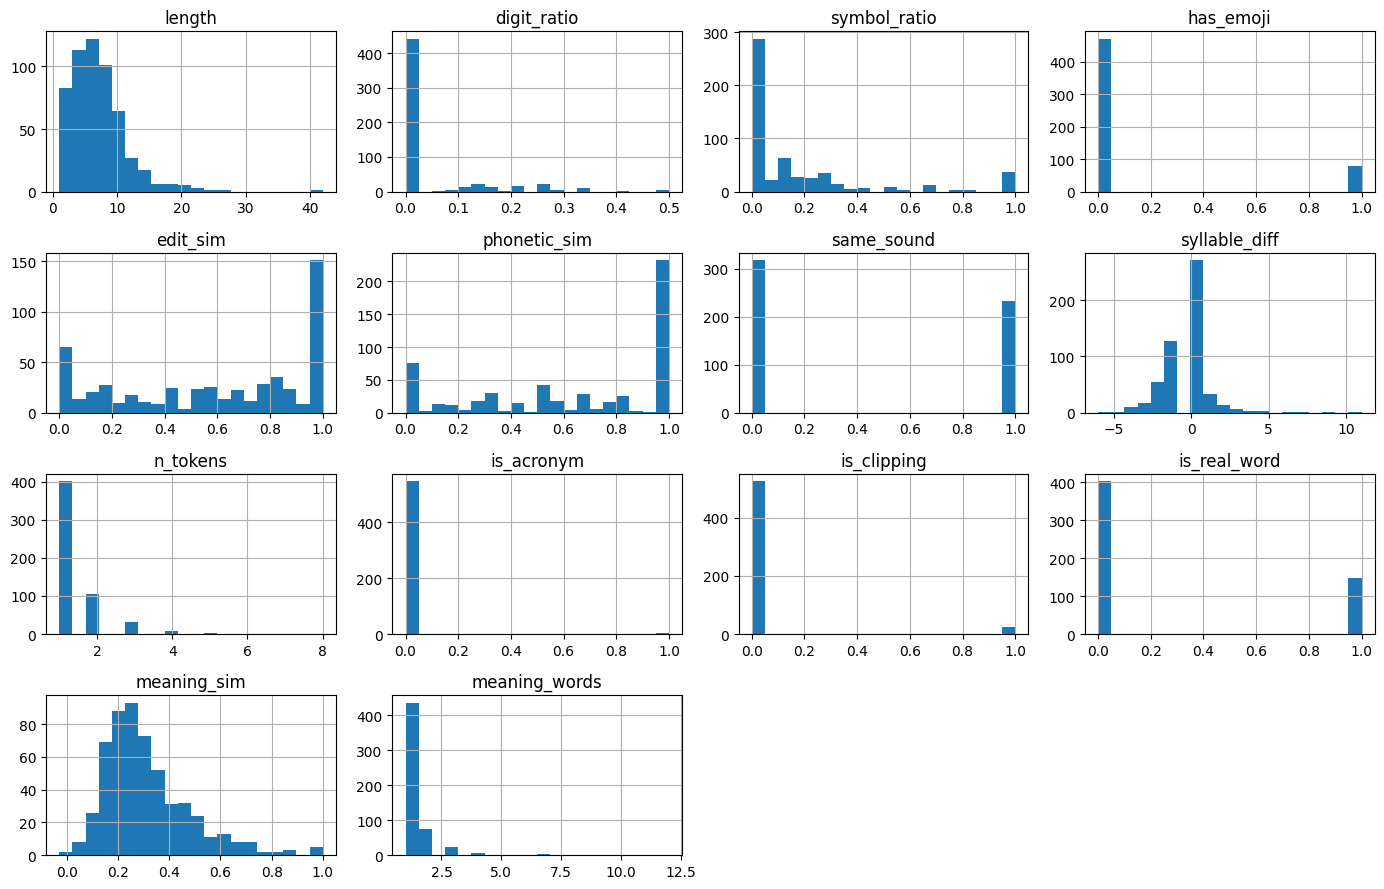

Components kept: 9 of 14


In [7]:
feat.hist(figsize=(14, 9), bins=20)
plt.tight_layout(); plt.show()

# NEW: keep the fitted scaler and the column list so we can transform new words later
cols   = feat.columns[feat.std() > 0].tolist()
scaler = StandardScaler().fit(feat[cols])
X      = scaler.transform(feat[cols])

pca = PCA(n_components=0.90, random_state=42)       # keep 90% of the variance
Xp = pca.fit_transform(X)
print("Components kept:", Xp.shape[1], "of", X.shape[1])

# **Clustering and evaluation**

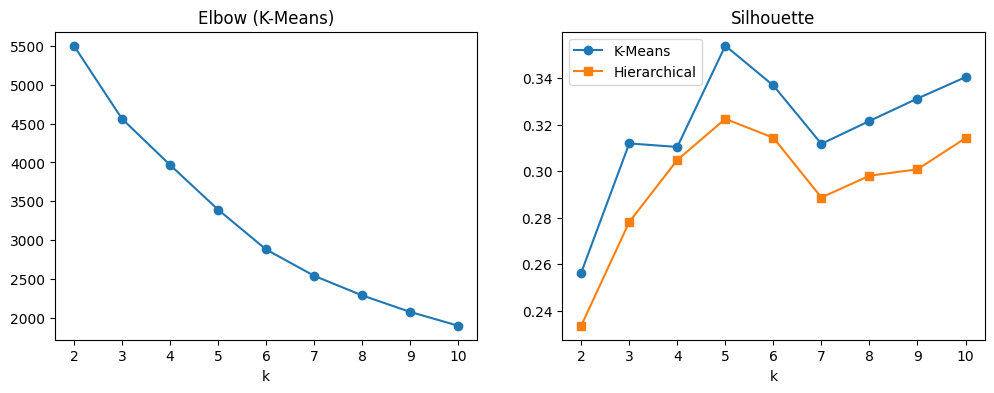

Chosen k: 5


In [8]:
ks = range(2, 11)
inertia, sil_km, sil_hc = [], [], []
for k in ks:
    km = KMeans(k, n_init=20, random_state=42).fit(Xp)
    inertia.append(km.inertia_)
    sil_km.append(silhouette_score(Xp, km.labels_))
    sil_hc.append(silhouette_score(Xp, AgglomerativeClustering(k, linkage="ward").fit_predict(Xp)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (K-Means)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil_km, "o-", label="K-Means")
ax[1].plot(ks, sil_hc, "s-", label="Hierarchical")
ax[1].set_title("Silhouette"); ax[1].set_xlabel("k"); ax[1].legend()
plt.show()

best_k = list(ks)[int(np.argmax(sil_km))]      # change manually if the elbow suggests another k
print("Chosen k:", best_k)

# **Cluster graphs and interpretation**

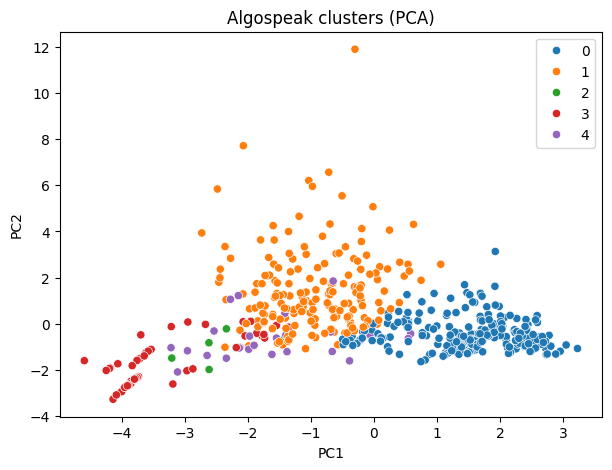

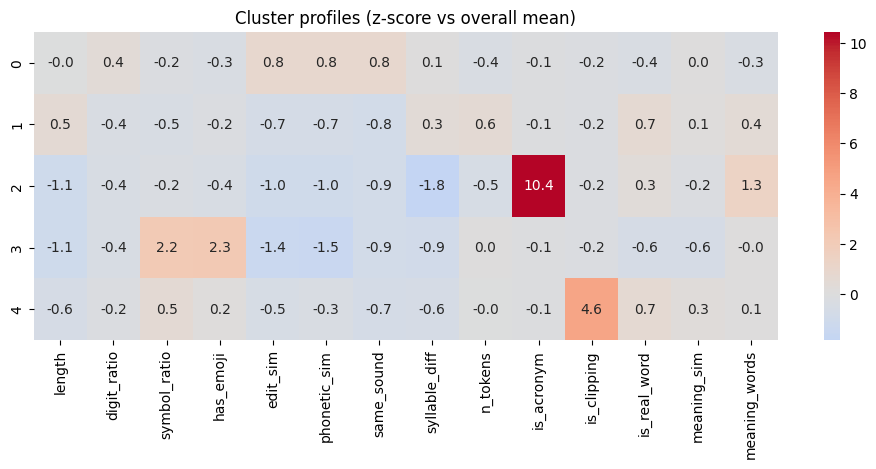


Cluster 0 (n=276):
algospeak  meaning
🅱 ully!ng bullying
 !nsanity insanity
 @bducted abducted
  @lc0h0l  alcohol
     @nal     anal
 @norex!a anorexia

Cluster 1 (n=183):
  algospeak                 meaning
    🆎 usive                 abusive
    😋 me up            eating me up
  🌈 couples           queer couples
  🌶 creator porn / onlyfans creator
💩 supporter         Trump supporter
   ⚪ people            white people

Cluster 2 (n=5):
algospeak             meaning
       AF             as fuck
       DV   domestic violence
    IDGAF I don’t give a fuck
       S@      sexual assault
       SA       sexual assult

Cluster 3 (n=61):
algospeak     meaning
       🇮🇱      Israel
       🇵🇸   Palestine
        🏳 gay / queer
        🌈 gay / LGBTQ
        ✡      Jewish
        🍉   Palestine

Cluster 4 (n=25):
algospeak  meaning
  $hittin shitting
        B    bitch
  c0mment comments
       D-      die
      d0m dominant
    dr***    drugs


In [9]:
km = KMeans(best_k, n_init=50, random_state=42).fit(Xp)
df["cluster"] = km.labels_

# cluster scatter plot
p2 = PCA(2).fit_transform(X)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=p2[:, 0], y=p2[:, 1], hue=km.labels_, palette="tab10")
plt.title("Algospeak clusters (PCA)"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

# which features define each cluster?
profile = feat.groupby(km.labels_).mean()
profile = (profile - feat.mean()) / feat.std()
plt.figure(figsize=(12, 4))
sns.heatmap(profile, cmap="coolwarm", center=0, annot=True, fmt=".1f")
plt.title("Cluster profiles (z-score vs overall mean)")
plt.show()

# example words per cluster
for c in range(best_k):
    print(f"\nCluster {c} (n={(km.labels_ == c).sum()}):")
    print(df[df.cluster == c].head(6)[["algospeak", "meaning"]].to_string(index=False))

# **Name the clusters**

> Run the previous cell first and check the example words. K-Means numbers can shuffle when the data changes, so match each number to the right name below.

In [10]:
CLUSTER_NAMES = {
    0: "Look-alike leetspeak",          # high edit_sim / phonetic_sim / same_sound
    1: "Real-word swaps & phrases",     # more tokens, real words, low similarity
    2: "Acronyms",                      # is_acronym very high
    3: "Emoji & symbol codes",          # symbol_ratio + has_emoji high, similarity low
    4: "Clippings & censored stubs",    # is_clipping very high
}
df["cluster_name"] = df.cluster.map(CLUSTER_NAMES)
df.groupby(["cluster", "cluster_name"]).size()

,,0
cluster,cluster_name,
0,Look-alike leetspeak,276
1,Real-word swaps & phrases,183
2,Acronyms,5
3,Emoji & symbol codes,61
4,Clippings & censored stubs,25


# **Predictive Analysis & Testing Unseen Words**

> **Predictive Analysis Engine:** Works for words **in** the dataset (instant lookup) and words **not** in it. For unseen words that do not exist in the dataset, our model automatically infers the most probable decoded meaning using lexical distance, Metaphone phonetic resemblance, semantic embeddings (`SentenceTransformer`), analog pattern transfer from known variants, and structural obfuscation rules (leetspeak, acronyms, clippings, masked letters). It then extracts all 14 features, projects the word into the PCA space, and assigns the nearest cluster family.


In [11]:
WILDCARDS = set(['*', '_', '?', '\u2022', '.', '-'])
EMOJI_LETTERS = {'\U0001f171': 'b', '\U0001f18e': 'ab', '\U0001f17e': 'o', '\U0001f170': 'a'}

def predict_meaning(query: str, top_k: int = 5):
    """Predict the decoded meaning of an unseen algospeak word using a multi-strategy model."""
    q = query.strip()
    a = unleet(q)
    q_emb = emb.encode([q], normalize_embeddings=True)[0]
    sem_to_meaning = np.clip(Em @ q_emb, 0, 1)
    sem_to_alg = np.clip(Ea @ q_emb, 0, 1)
    
    wild = None
    if any(c in WILDCARDS for c in q) and len(re.sub(r'[^a-z0-9@$!*_?•.-]', '', q.lower())) >= 2:
        pat = ''.join('.' if c in WILDCARDS else LEET.get(c, c) for c in q.lower() if c.isalnum() or c in WILDCARDS or c in LEET)
        try:
            wild = re.compile('^' + pat)
        except re.error:
            wild = None

    scores = []
    for i, (alg, mean) in enumerate(zip(df.algospeak, df.meaning)):
        t = target_of(mean)
        initials = ''.join(w[0].lower() for w in mean.split())
        
        # 1. Direct lexical + phonetic + semantic similarity to candidate meaning
        lex_sim = sim(a, t)
        phon_sim = sim(jellyfish.metaphone(a), jellyfish.metaphone(t))
        direct = 0.45 * lex_sim + 0.30 * phon_sim + 0.25 * sem_to_meaning[i]
        
        # 2. Analog mutation similarity to known algospeak entries
        alg_u = unleet(alg)
        analog = 0.90 * sim(a, alg_u) if a and alg_u else 0.0
        
        # 3. Structural bonuses
        bonus = 0.0
        if wild and wild.match(t):
            bonus += 0.40
        if len(a) >= 2 and a == initials:
            bonus += 0.45
        if 0 < len(a) < len(t) and t.startswith(a) and len(a) >= 3:
            bonus += 0.25
            
        final_score = min(1.0, max(direct, analog) + bonus + 0.15 * sem_to_alg[i])
        scores.append((final_score, mean, alg))

    cand = pd.DataFrame(scores, columns=['confidence', 'meaning', 'nearest_algospeak'])
    best = cand.sort_values('confidence', ascending=False).drop_duplicates('meaning').head(top_k).reset_index(drop=True)
    return best

def explain_disguise(alg: str, meaning: str) -> list:
    """Analyze and explain the specific linguistic disguise mechanisms used."""
    reasons = []
    q_low = alg.lower()
    subs = [(c, LEET[c]) for c in q_low if c in LEET]
    if subs:
        reasons.append('Leetspeak symbol swap: ' + ', '.join(f"'{a}'→'{b}'" for a, b in dict.fromkeys(subs)))
    if any(c in EMOJI_LETTERS for c in alg):
        reasons.append('Emoji letter stand-in (e.g. 🅱 = b)')
    if any(c in WILDCARDS for c in alg):
        reasons.append('Masked characters / asterisks (censored word)')
    elif EMOJI.search(alg):
        reasons.append('Emoji / symbolic visual code')
    t = target_of(meaning)
    a = unleet(alg)
    initials = ''.join(w[0].lower() for w in meaning.split())
    if len(a) >= 2 and a == initials:
        reasons.append('Acronym / initialism of decoded phrase')
    if 0 < len(a) < len(t) and t.startswith(a):
        reasons.append('Clipping / truncated prefix')
    if jellyfish.metaphone(a) == jellyfish.metaphone(t) and a != '' and sim(a, t) < 0.8:
        reasons.append('Phonetic respelling / homophone (sounds identical)')
    elif sim(jellyfish.metaphone(a), jellyfish.metaphone(t)) > 0.6 and sim(a, t) < 0.8:
        reasons.append('Phonetic sound-alike / near-homophone')
    if not reasons:
        reasons.append('Semantic euphemism / code word')
    return reasons

def analyze_word(alg, meaning=None, n_similar=5, plot=True):
    alg = alg.strip()
    hit = df[df.algospeak.str.lower() == alg.lower()]

    if len(hit):
        print(f'=== [KNOWN ENTRY] Found in dataset ===')
        for i, r in hit.iterrows():
            print(f"{r.algospeak} -> {r.meaning}")
            print(f"Cluster {r.cluster}: {r.cluster_name}")
            print(feat.loc[i].round(2).to_string())
        return

    is_predicted = False
    if meaning is None:
        print(f"=== [PREDICTIVE ANALYSIS] '{alg}' not in dataset — Inferring meaning ===")
        preds = predict_meaning(alg, top_k=n_similar)
        print('\nTop Predictions:')
        for idx, row in preds.iterrows():
            pct = int(row['confidence'] * 100)
            print(f"  {idx+1}. '{row['meaning']}' (Confidence: {pct}%, Nearest Known: '{row['nearest_algospeak']}')")
        meaning = preds.iloc[0]['meaning']
        is_predicted = True
        print(f"\nProceeding with top prediction: '{meaning}'")

    # Compute all 14 features
    c = float((emb.encode([alg], normalize_embeddings=True) * emb.encode([meaning], normalize_embeddings=True)).sum())
    f = pd.DataFrame([extract(alg, meaning, c)])
    x_scaled = scaler.transform(f[cols])
    cl = int(km.predict(pca.transform(x_scaled))[0])
    xy = pca2.transform(x_scaled)[0]
    disguises = explain_disguise(alg, meaning)

    print(f"\n{alg} -> {meaning} {'[PREDICTED]' if is_predicted else '[CUSTOM]'}")
    print(f"Assigned Cluster {cl}: {CLUSTER_NAMES.get(cl)}")
    print(f"PCA Coordinates: x={xy[0]:.2f}, y={xy[1]:.2f}")
    print(f"Disguise tactics: {'; '.join(disguises)}\n")
    z = (f[cols].iloc[0] - feat[cols].mean()) / feat[cols].std()
    print(pd.DataFrame({'value': f[cols].iloc[0].round(2), 'dataset_avg': feat[cols].mean().round(2), 'z': z.round(1)}).to_string())
    
    if plot:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(x=p2[:, 0], y=p2[:, 1], hue=km.labels_, palette='tab10', alpha=0.5)
        plt.scatter(xy[0], xy[1], color='red', s=160, marker='*', label=f'New: {alg} ({meaning})', edgecolors='black', zorder=5)
        plt.title(f'PCA Placement: {alg} -> {meaning}')
        plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout(); plt.show()


Found 1 match(es) in the dataset

@lc0h0l  ->  alcohol
Cluster 0: Look-alike leetspeak
length           7.00
digit_ratio      0.29
symbol_ratio     0.14
has_emoji        0.00
edit_sim         1.00
phonetic_sim     1.00
same_sound       1.00
syllable_diff    0.00
n_tokens         1.00
is_acronym       0.00
is_clipping      0.00
is_real_word     0.00
meaning_sim      0.14
meaning_words    1.00
Found 1 match(es) in the dataset

s3gs  ->  sex
Cluster 0: Look-alike leetspeak
length           4.00
digit_ratio      0.25
symbol_ratio     0.00
has_emoji        0.00
edit_sim         0.50
phonetic_sim     1.00
same_sound       1.00
syllable_diff    0.00
n_tokens         1.00
is_acronym       0.00
is_clipping      0.00
is_real_word     1.00
meaning_sim      0.23
meaning_words    1.00
Found 1 match(es) in the dataset

s3gs  ->  sex
Cluster 0: Look-alike leetspeak
length           4.00
digit_ratio      0.25
symbol_ratio     0.00
has_emoji        0.00
edit_sim         0.50
phonetic_sim     1.00
same_

In [ ]:
# Demonstration of Predictive Analysis on unseen algospeak words
print('=== Example 1: Leetspeak / phonetic respelling ===')
analyze_word('seggs', plot=False)

print('\n=== Example 2: Wildcard / masked word clipping ===')
analyze_word('dr***', plot=False)

print('\n=== Example 3: Social media euphemism ===')
analyze_word('unalive', plot=False)


# **Export for the UI**

> Creates `algospeak_data.json` (all rows, features, clusters, PCA coordinates, cluster profiles). Download it and add it to the interactive page.

In [12]:
import json

records = []
for i, r in df.iterrows():
    records.append({
        'algospeak': r.algospeak, 'meaning': r.meaning,
        'cluster': int(r.cluster), 'cluster_name': r.cluster_name,
        'x': round(float(p2[i, 0]), 3), 'y': round(float(p2[i, 1]), 3),
        **{c: round(float(feat.loc[i, c]), 3) for c in feat.columns},
    })

z_all   = (feat[cols] - feat[cols].mean()) / feat[cols].std()
prof_z  = z_all.groupby(km.labels_).mean()

out = {
    'rows': records,
    'cols': cols,
    'mean': feat[cols].mean().round(4).tolist(),
    'std':  feat[cols].std().round(4).tolist(),
    'profile': prof_z.values.round(3).tolist(),
    'cluster_names': {str(k): v for k, v in CLUSTER_NAMES.items()},
    'cluster_sizes': {str(k): int(v) for k, v in df.cluster.value_counts().sort_index().items()},
    'silhouette': {'k': list(ks), 'kmeans': [round(v, 4) for v in sil_km], 'hier': [round(v, 4) for v in sil_hc]},
}
with open('algospeak_data.json', 'w', encoding='utf-8') as fh:
    json.dump(out, fh, ensure_ascii=False, indent=2)
print('Saved algospeak_data.json:', len(records), 'rows (all 550 entries)')


Saved algospeak_data.json: 550 rows
